# Elegibilidad de mesas bajo FRTB: la prueba de atribución de P&L y el backtest de mesa (C13)

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 03 de este tema (backtests y el semáforo)
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar los dos estadísticos de la prueba de atribución de pérdidas y ganancias (PLA), la correlación de Spearman y la distancia de Kolmogorov-Smirnov, calcularlos a mano y obtener los valores del motor y los versionados;
- leer las zonas de la PLA y decir por qué el motor decide los límites sobre enteros;
- decir qué cuenta un backtest a nivel de mesa, cuáles son sus límites y cómo se trata un valor faltante;
- leer, para seis deficiencias plantadas en una mesa sintética, cuáles atrapa la PLA, cuáles deja pasar y qué estadístico las atrapa;
- dar el intervalo de 95 por ciento de una tasa de detección y decir qué puede y qué no puede afirmar una proporción de Monte Carlo sobre una verdad conocida.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# Los valores de luz del motor, con las palabras que imprime este cuaderno
LIGHT = {"green": "verde", "amber": "ámbar", "red": "rojo", "not_evaluated": "no evaluada"}

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C13 pregunta qué concluye un validador cuando el modelo de riesgo de una mesa tiene una deficiencia conocida. Los datos son **sintéticos por diseño**: un generador produce el P&L hipotético (HPL, de la revaluación exacta de la mesa) y el P&L teórico del riesgo (RTPL, del modelo de riesgo) de una mesa de spread de dos factores, y se planta una deficiencia solo en el modelo de riesgo. Como la verdad es conocida, cada resultado se muestra junto a la deficiencia que debe detectar. No es el libro de ninguna mesa real y no dice nada sobre ningún banco.

- `data/derived/C13/models-generator.json`: el generador, sus parámetros, los umbrales de la PLA y los límites de la mesa.
- `data/derived/C13/<variante>.json` para seis variantes: `none` (sin deficiencia, el tamaño de la prueba), `missing-basis`, `stale-volatility`, `wrong-correlation`, `omitted-factor` y `time-misalignment`. Cada una guarda 1.000 replicaciones de 250 días resumidas (zonas, conteos de detección, conteos de excepciones) y **una replicación de ejemplo** con sus dos series de P&L de 250 días, la replicación que tiene el estadístico de Spearman mediano.
- `data/derived/C11/fx-2008.json` aporta datos reales para el backtest a nivel de mesa del paso 4.

El cuaderno recalcula la prueba sobre las seis replicaciones de ejemplo y lee los resúmenes de las 1.000. La celda siguiente carga los archivos e imprime las deficiencias plantadas.

In [2]:
# Cargar el documento del generador y las seis variantes, e imprimir la deficiencia plantada de cada una con sus parámetros
ROOT = Path("../../..").resolve()
VARIANTS = ("none", "missing-basis", "stale-volatility", "wrong-correlation", "omitted-factor", "time-misalignment")
c13 = {v: json.loads((ROOT / "data" / "derived" / "C13" / f"{v}.json").read_text(encoding="utf-8")) for v in VARIANTS}
generator = json.loads((ROOT / "data" / "derived" / "C13" / "models-generator.json").read_text(encoding="utf-8"))["fit"]
print("filas versionadas calculadas por riskvalidation", c13["none"]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)
print("estado de la verdad:", c13["none"]["provenance"]["truth_status"], "|", generator["generator"]["notice"]["es"][:60] + "...")
print("umbrales de la PLA:", {k: v for k, v in generator["pla_thresholds"].items() if k != "reference"}, "| límites de la mesa:", {d["alpha"]: d["limit_exceptions"] for d in generator["desk_limits"]})
for v in VARIANTS:
    known = c13[v]["outputs"]["known_deficiency"]
    print(f"{v:18s} plantada {known['planted']!s:5s} debe fallar: {known['intended_to_fail']:9s} parámetros {[(p['name'], p['value']) for p in known['parameters']]}")

filas versionadas calculadas por riskvalidation 0.7.0 | instalado 0.8.1
estado de la verdad: synthetic-known-truth | Datos sintéticos: es un P&L de mesa generado con un modelo d...
umbrales de la PLA: {'spearman_green': 0.8, 'spearman_red': 0.7, 'ks_green': 0.09, 'ks_red': 0.12, 'ecdf_step': 0.004, 'window_days': 250} | límites de la mesa: {0.025: 30, 0.01: 12}
none               plantada False debe fallar: none      parámetros []
missing-basis      plantada True  debe fallar: spearman  parámetros [('basis_sd_share', 0.65)]
stale-volatility   plantada True  debe fallar: ks        parámetros [('vol_lag_days', 20.0)]
wrong-correlation  plantada True  debe fallar: either    parámetros [('correlation_error', 0.3)]
omitted-factor     plantada True  debe fallar: spearman  parámetros [('omitted_loading_share', 0.6)]
time-misalignment  plantada True  debe fallar: spearman  parámetros [('lag_days', 1.0)]


## Método

### Paso 1: la prueba PLA

El enfoque de modelos internos de FRTB (Marco de Basilea, MAR32.36 a MAR32.42) pregunta si el modelo de riesgo explica el P&L de la mesa. Sobre los 250 días más recientes compara el P&L teórico del riesgo con el hipotético de dos maneras. La **correlación de Spearman** es la correlación de Pearson de los rangos, así que pregunta si las dos series ordenan los días de igual modo:

$$r_S = \frac{\operatorname{cov}(R_{HPL}, R_{RTPL})}{\sigma_{R_{HPL}}\,\sigma_{R_{RTPL}}}$$

La distancia de **Kolmogorov-Smirnov** pregunta si las dos series tienen la misma distribución, con la función de distribución empírica $F(x) = 0{,}004\cdot\#\{\text{observaciones} \le x\}$:

$$KS = \sup_x \left| F_{RTPL}(x) - F_{HPL}(x) \right|$$

La zona es **verde** si $r_S > 0{,}80$ y $KS < 0{,}09$, **roja** si $r_S < 0{,}70$ o $KS > 0{,}12$, **ámbar** en otro caso. Rojo deja a la mesa inelegible para el enfoque de modelos internos; ámbar la mantiene con un recargo de capital. Las funciones `pla_spearman`, `pla_ks`, `pla_zone` y `pla_test` del motor las implementan. La celda calcula ambos estadísticos a mano sobre la replicación de ejemplo de la variante `none`, con la correlación de rangos de SciPy y un conteo de los escalones de las dos funciones de distribución, y los compara con el motor y la fila versionada.

In [3]:
# Spearman y Kolmogorov-Smirnov a mano sobre la replicación de ejemplo de la variante "none", frente al motor y a la fila versionada
from riskvalidation.market.frtb import pla_ks, pla_spearman, pla_zone
from riskvalidation.validation.market import pla_test

example = c13["none"]["outputs"]["example"]
hpl, rtpl = np.array(example["hpl"]), np.array(example["rtpl"])
print(f"replicación {example['replication_index']} (semilla {example['seed']}): {hpl.size} días cada una | desviación estándar de HPL {hpl.std():.5f} | RTPL {rtpl.std():.5f}")

rho_by_hand = stats.spearmanr(hpl, rtpl).statistic
points = np.union1d(hpl, rtpl)
ecdf_hpl = np.searchsorted(np.sort(hpl), points, side="right") * 0.004
ecdf_rtpl = np.searchsorted(np.sort(rtpl), points, side="right") * 0.004
ks_by_hand = float(np.max(np.abs(ecdf_rtpl - ecdf_hpl)))
print(f"a mano: Spearman {rho_by_hand:.6f} | KS {ks_by_hand:.3f}")
print(f"motor : Spearman {pla_spearman(hpl, rtpl):.6f} | KS {pla_ks(hpl, rtpl):.3f} | zona {pla_zone(pla_spearman(hpl, rtpl), pla_ks(hpl, rtpl))}")

result = pla_test(hpl, rtpl, model_id="desk-risk-model")
row = [t for t in c13["none"]["tests"] if t["test_id"] == "market.pla_test"][0]
print(f"pla_test  : estadístico {result.statistic:.6f} | métrica {result.metric:.3f} | luz {LIGHT[result.light.value]}")
print(f"versionado: estadístico {row['statistic']:.6f} | métrica {row['metric']:.3f} | luz {LIGHT[row['light']]}")

replicación 9 (semilla 13009): 250 días cada una | desviación estándar de HPL 0.00529 | RTPL 0.00522
a mano: Spearman 0.992332 | KS 0.032
motor : Spearman 0.992332 | KS 0.032 | zona green
pla_test  : estadístico 0.992332 | métrica 0.032 | luz verde
versionado: estadístico 0.992332 | métrica 0.032 | luz verde


### Paso 2: límites decididos sobre enteros

Un límite de zona es una línea dura, y un estadístico que cae exactamente sobre ella no debe ser movido por el redondeo de punto flotante. La distancia KS es un conteo entero de escalones sobre 250, así que $KS < 0{,}09$ es $\text{brecha} \le 22$ y $KS > 0{,}12$ es $\text{brecha} \ge 31$. Los límites de Spearman 0,80 y 0,70 los decide `compare_spearman`, que trabaja con los rangos promedio duplicados como enteros y compara $S_{xy}^2$ con $\text{umbral}^2\,S_{xx}S_{yy}$ en aritmética racional exacta, y devuelve 1, 0 o -1 para encima, sobre y debajo. `pla_zone_exact` usa ambos y coincide con la regla de punto flotante `pla_zone` salvo donde un cociente en punto flotante caería sobre un límite. La celda imprime, para la replicación de ejemplo de cada variante, la brecha de escalones, la comparación con cada límite de Spearman y las dos reglas de zona.

In [4]:
# Para el ejemplo de cada variante: la brecha de escalones KS, la comparación exacta con cada límite de Spearman y las reglas de zona flotante y exacta
from riskvalidation.market.frtb import compare_spearman, pla_zone_exact

print(f"{'variante':18s} {'Spearman':>9s} {'KS':>6s} {'brecha':>6s} {'vs 0.80':>8s} {'vs 0.70':>8s}  {'zona flot.':10s} {'zona exacta':11s}")
for v in VARIANTS:
    example = c13[v]["outputs"]["example"]
    h, r = np.array(example["hpl"]), np.array(example["rtpl"])
    rho, ks = pla_spearman(h, r), pla_ks(h, r)
    print(f"{v:18s} {rho:9.4f} {ks:6.3f} {round(ks * 250):6d} {compare_spearman(h, r, 0.80):8d} {compare_spearman(h, r, 0.70):8d}  "
          f"{LIGHT[pla_zone(rho, ks)]:10s} {LIGHT[pla_zone_exact(h, r)]:11s}")

variante            Spearman     KS brecha  vs 0.80  vs 0.70  zona flot. zona exacta
none                  0.9923  0.032      8        1        1  verde      verde      
missing-basis         0.7107  0.104     26       -1        1  ámbar      ámbar      
stale-volatility      0.9793  0.044     11        1        1  verde      verde      
wrong-correlation     0.9865  0.144     36        1        1  rojo       rojo       
omitted-factor        0.7749  0.080     20       -1        1  ámbar      ámbar      
time-misalignment    -0.0065  0.028      7       -1       -1  rojo       rojo       


### Paso 3: las seis replicaciones de ejemplo frente a las filas versionadas

Una replicación es un sorteo, pero muestra el mecanismo: cada deficiencia deja una marca distinta en los dos estadísticos. La celda recalcula `pla_test` sobre el ejemplo de cada variante y lo verifica contra la fila `market.pla_test` versionada, y dibuja el RTPL contra el HPL de cada una. Una **base omitida** o un **factor omitido** agrega P&L que el modelo no puede ver, lo que debilita la correlación de rangos; un **desfase temporal** destruye por completo la correspondencia día a día; una **correlación equivocada** mantiene el orden de los días pero cambia la dispersión del P&L del modelo, lo que la distancia KS ve y la correlación de Spearman no; una **volatilidad rezagada** cambia poco de ambos.

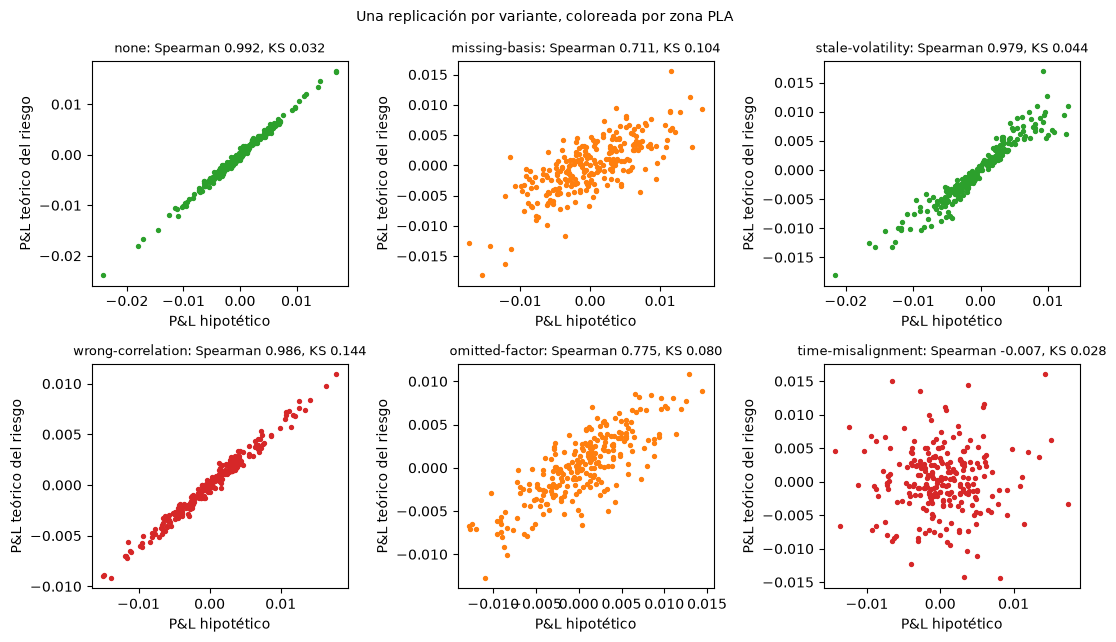

mayor diferencia con las filas versionadas, seis variantes: 4.1e-10; cada zona igual a la versionada


In [5]:
# Recalcular pla_test sobre el ejemplo de cada variante y compararlo con la fila versionada, y luego dibujar RTPL contra HPL
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
colour = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
worst = 0.0
for ax, v in zip(axes.ravel(), VARIANTS):
    example = c13[v]["outputs"]["example"]
    h, r = np.array(example["hpl"]), np.array(example["rtpl"])
    fresh = pla_test(h, r, model_id="desk-risk-model")
    row = [t for t in c13[v]["tests"] if t["test_id"] == "market.pla_test"][0]
    worst = max(worst, abs(fresh.statistic - row["statistic"]), abs(fresh.metric - row["metric"]))
    assert fresh.light.value == row["light"]
    ax.scatter(h, r, s=8, color=colour[fresh.light.value])
    ax.set_title(f"{v}: Spearman {fresh.statistic:.3f}, KS {fresh.metric:.3f}", fontsize=9)
    ax.set_xlabel("P&L hipotético")
    ax.set_ylabel("P&L teórico del riesgo")
fig.suptitle("Una replicación por variante, coloreada por zona PLA", fontsize=10)
fig.tight_layout()
plt.show()
print(f"mayor diferencia con las filas versionadas, seis variantes: {worst:.1e}; cada zona igual a la versionada")

### Paso 4: el backtest a nivel de mesa

Además de la prueba PLA, una mesa de modelos internos debe someter a backtest su VaR a nivel de mesa (MAR32.18 a MAR32.19): sobre los 250 días más recientes cuenta los días en que la pérdida superó al VaR a un día de la mesa, y la mesa **pasa al enfoque estandarizado** si el conteo excede 12 al 99 por ciento o 30 al 97,5 por ciento. El motor tiene `desk_exception_limit(alpha)`, `desk_exceptions(loss, var, missing_as_exception)` y `desk_backtest(loss, var, alpha, basis)`. Una pérdida o un VaR faltante cuenta como excepción por defecto, ya que el marco trata un valor faltante como un valor atípico en el backtest de todo el banco y el motor mantiene la misma regla para una mesa tras una bandera. No hay ámbar: la luz es roja sobre el límite y verde en otro caso.

Las mesas sintéticas de C13 versionan sus conteos de excepciones pero no las series de pérdida y VaR, así que este paso usa datos reales: la posición en euros de `fx-2008` como una mesa de una sola posición, su pérdida realizada y el VaR `ewma` versionado para los últimos 250 de sus 251 días. La celda muestra el conteo, el límite y la luz en ambos niveles, y luego deja en blanco dos días para mostrar el tratamiento de los valores faltantes.

In [6]:
# Backtest de mesa de la posición en euros (una mesa de una posición): excepciones en los últimos 250 días frente al límite, y valores faltantes
from riskvalidation.market.frtb import desk_exception_limit, desk_exceptions
from riskvalidation.validation.market import desk_backtest

fx = json.loads((ROOT / "data" / "derived" / "C11" / "fx-2008.json").read_text(encoding="utf-8"))
fx_loss = np.array(fx["outputs"]["grid"]["realised_loss"]["loss"])
ewma = {m["model_id"]: m for m in fx["outputs"]["models"]}["ewma"]
for level in ewma["by_level"]:
    alpha = level["alpha"]
    var = np.array(level["var"])
    outcome = desk_backtest(fx_loss, var, alpha, model_id="ewma", basis="HPL")
    print(f"alfa {alpha}: excepciones en los últimos 250 días {int(outcome.statistic)} | límite {int(outcome.metric)} | luz {LIGHT[outcome.light.value]}")

alpha = 0.01
var = np.array(ewma["by_level"][0]["var"])
blanked = fx_loss.copy()
blanked[[100, 101]] = np.nan                                   # dos días sin P&L
print("límites:", {a: desk_exception_limit(a) for a in (0.01, 0.025)})
print(f"faltantes contados como excepciones: {desk_exceptions(blanked[-250:], var[-250:])} | faltantes ignorados: "
      f"{desk_exceptions(blanked[-250:], var[-250:], missing_as_exception=False)} | sin valores faltantes: {desk_exceptions(fx_loss[-250:], var[-250:])}")

alfa 0.01: excepciones en los últimos 250 días 3 | límite 12 | luz verde
alfa 0.025: excepciones en los últimos 250 días 8 | límite 30 | luz verde
límites: {0.01: 12, 0.025: 30}
faltantes contados como excepciones: 5 | faltantes ignorados: 3 | sin valores faltantes: 3


### Paso 5: con qué frecuencia se atrapa cada deficiencia

Lo que un validador necesita saber no es si la prueba atrapó una replicación sino con qué **frecuencia**. Cada variante corrió 1.000 replicaciones, y el artefacto registra cuántas fueron ámbar o rojas en la PLA (la deficiencia es **atrapada**), cuántas fueron rojas, cuántas superaron el límite de la mesa al 99 por ciento, y qué estadístico las marcó. Para la variante sin deficiencia la misma proporción es la **tasa de falsa alarma** (el tamaño de la prueba). Una proporción $\hat p$ de $n$ replicaciones lleva error de Monte Carlo: el error estándar es $\sqrt{\hat p(1-\hat p)/n}$, que es cero en 0 y 1, así que el artefacto informa el intervalo de puntaje de Wilson, que queda dentro de [0, 1] y no es degenerado en los bordes (Brown, Cai y DasGupta, 2001). La celda lee las proporciones, recalcula el intervalo a mano y lo compara con el versionado.

In [7]:
# Proporciones de detección de las 1.000 replicaciones por variante, con el intervalo de Wilson recalculado a mano frente al versionado
z = 1.96
print(f"{'variante':18s} {'atrapadas':>9s} {'rojas':>6s} {'mesa>12':>8s} {'Spearman':>9s} {'KS':>5s} {'intervalo (a mano)':>22s} {'(versionado)':>20s}")
interval_gap = 0.0
for v in VARIANTS:
    out = c13[v]["outputs"]
    det = out["detection"]
    n, k = det["n_replications"], det["n_amber_or_red"]
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    interval_gap = max(interval_gap, abs(centre - half - det["ci_low"]), abs(centre + half - det["ci_high"]))
    by = det["by_test"]
    print(f"{v:18s} {p:9.3f} {det['share_red']:6.3f} {c13[v]['impact']['share_desk_over_limit_99']['value']:8.3f} {by['spearman_flagged']:9d} {by['ks_flagged']:5d} "
          f"{centre - half:11.4f} a {centre + half:7.4f} {det['ci_low']:9.4f} a {det['ci_high']:7.4f}")
print(f"mayor diferencia entre el intervalo a mano y el versionado: {interval_gap:.1e}")

variante           atrapadas  rojas  mesa>12  Spearman    KS     intervalo (a mano)         (versionado)
none                   0.000  0.000    0.000         0     0      0.0000 a  0.0038    0.0000 a  0.0038
missing-basis          0.960  0.575    0.565       919   867      0.9460 a  0.9705    0.9460 a  0.9705
stale-volatility       0.000  0.000    0.005         0     0      0.0000 a  0.0038    0.0000 a  0.0038
wrong-correlation      1.000  0.913    0.953         0  1000      0.9962 a  1.0000    0.9962 a  1.0000
omitted-factor         0.901  0.043    0.064       805   448      0.8809 a  0.9180    0.8809 a  0.9180
time-misalignment      1.000  1.000    0.000      1000     0      0.9962 a  1.0000    0.9962 a  1.0000
mayor diferencia entre el intervalo a mano y el versionado: 4.3e-10


La última figura dibuja las proporciones de detección: para cada variante la proporción de replicaciones atrapadas por la PLA (ámbar o roja), la proporción roja y la proporción sobre el límite de la mesa al 99 por ciento, con el intervalo de Wilson en la primera. La variante sin deficiencia muestra la tasa de falsa alarma; las otras muestran la potencia frente a una deficiencia del tamaño declarado.

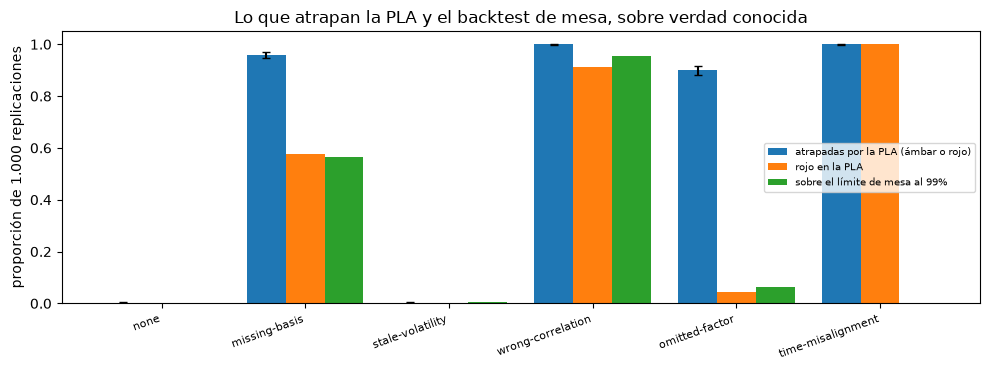

In [8]:
# Dibujar la proporción atrapada, la proporción roja y la proporción sobre el límite de mesa al 99% de cada variante, con el intervalo versionado
fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.27
positions = np.arange(len(VARIANTS))
caught = np.array([c13[v]["outputs"]["detection"]["share_amber_or_red"] for v in VARIANTS])
low = np.array([c13[v]["outputs"]["detection"]["ci_low"] for v in VARIANTS])
high = np.array([c13[v]["outputs"]["detection"]["ci_high"] for v in VARIANTS])
red = np.array([c13[v]["impact"]["share_red"]["value"] for v in VARIANTS])
desk = np.array([c13[v]["impact"]["share_desk_over_limit_99"]["value"] for v in VARIANTS])
ax.bar(positions - width, caught, width, yerr=[caught - low, high - caught], capsize=3, label="atrapadas por la PLA (ámbar o rojo)")
ax.bar(positions, red, width, label="rojo en la PLA")
ax.bar(positions + width, desk, width, label="sobre el límite de mesa al 99%")
ax.set_xticks(positions)
ax.set_xticklabels(VARIANTS, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("proporción de 1.000 replicaciones")
ax.set_title("Lo que atrapan la PLA y el backtest de mesa, sobre verdad conocida")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Resultados

- **Los estadísticos a mano.** En la replicación de ejemplo de la variante `none` (replicación 9, semilla 13009) la correlación de Spearman es 0,992332 y la distancia KS 0,032 (una brecha de 8 escalones de 250) a mano, con el motor y en la fila versionada, y la zona es verde. Para los seis ejemplos la mayor diferencia con las filas `pla_test` versionadas es 4,1e-10 y cada zona es la versionada.
- **Límites sobre enteros.** `missing-basis` (Spearman 0,7107, brecha 26) y `omitted-factor` (0,7749, brecha 20) son ámbar porque su Spearman está entre 0,70 y 0,80 (comparación -1 contra 0,80, +1 contra 0,70). `wrong-correlation` tiene un Spearman de 0,9865 y una brecha de 36, más allá del límite rojo de 31, así que es roja solo por KS. `time-misalignment` tiene un Spearman de -0,0065 y es roja. La regla de punto flotante y la exacta coinciden en las seis.
- **El backtest de mesa.** Tratando la posición en euros de `fx-2008` como una mesa de una posición, el VaR `ewma` tiene 3 excepciones en los últimos 250 días al 99 por ciento (límite 12) y 8 al 97,5 por ciento (límite 30): verde en ambos. Con dos días de P&L faltante el conteo es 5 cuando los valores faltantes cuentan como excepciones, el valor por defecto, y 3 cuando se ignoran.
- **Falsas alarmas.** Sin deficiencia la PLA es ámbar o roja en 0 de 1.000 replicaciones, y el intervalo de 95 por ciento de esa proporción termina en 0,0038: la prueba casi nunca acusa a un modelo correcto en este generador.
- **Qué se atrapa.** `time-misalignment` se atrapa en 100 por ciento de las replicaciones (todas rojas, todas por Spearman), `wrong-correlation` en 100 por ciento (91,3 por ciento rojas, todas por KS, ninguna por Spearman), `missing-basis` en 96,0 por ciento (intervalo 0,946 a 0,970; 57,5 por ciento rojas; Spearman marca 919 y KS 867) y `omitted-factor` en 90,1 por ciento (0,881 a 0,918; solo 4,3 por ciento rojas). `stale-volatility`, un rezago de 20 días en la volatilidad de entrada, se atrapa en **0** de 1.000 replicaciones (límite superior 0,0038): la PLA, que el archivo marca como destinada a fallar en KS, no la ve.
- **El backtest de mesa atrapa un subconjunto distinto.** Supera su límite del 99 por ciento en 95,3 por ciento de las replicaciones de `wrong-correlation`, 56,5 por ciento de `missing-basis`, 6,4 por ciento de `omitted-factor`, 0,5 por ciento de `stale-volatility` y en ninguna de `time-misalignment`, que la PLA atrapa siempre. Ninguna de las dos pruebas domina a la otra.
- **El intervalo.** El intervalo de Wilson recalculado a mano coincide con el versionado con 4,3e-10. Es el intervalo de una proporción de Monte Carlo sobre un generador de verdad conocida; no dice nada de con qué frecuencia una mesa real tiene una de estas deficiencias.

Lo que este cuaderno no muestra: las consecuencias de capital de una mesa ámbar o roja (recargo o enfoque estandarizado), que pertenecen a las calculadoras regulatorias.

## Resumen

- La prueba PLA tiene dos estadísticos que ven cosas distintas: la correlación de Spearman ve si las dos series de P&L ordenan los días de igual modo, la distancia KS si tienen la misma distribución. Una deficiencia puede romper uno y dejar intacto el otro, así que la zona conjunta toma el peor de los dos.
- Los límites de zona se deciden sobre enteros (una brecha de escalones para KS, aritmética racional exacta para Spearman), de modo que un valor sobre un límite nunca lo mueve el redondeo.
- El backtest de mesa cuenta excepciones contra un límite (12 al 99 por ciento, 30 al 97,5 por ciento) sin ámbar, y un valor faltante cuenta como excepción por defecto.
- En una mesa sintética con una deficiencia plantada la verdad es conocida, así que la prueba se puede juzgar por su tasa de detección y su tasa de falsa alarma, cada una con un intervalo. La PLA atrapa algunas deficiencias casi siempre y otras nunca, y el backtest de mesa atrapa un subconjunto distinto.
- Una proporción de Monte Carlo sobre verdad conocida dice cómo se comporta la prueba en estos generadores; no dice con qué frecuencia una mesa real tiene estas deficiencias.

**Qué probar después.** Para una variante, toma el `rtpl` del ejemplo y desplázalo un día con `np.roll`, recalcula la zona y compárala con la variante `time-misalignment`; luego lee la descripción del generador en el SDD.

## Referencias

- Comité de Supervisión Bancaria de Basilea, Marco de Basilea, MAR32.18 a MAR32.19 (backtesting a nivel de mesa) y MAR32.36 a MAR32.42 (la prueba de atribución de pérdidas y ganancias), tal como los implementa `riskvalidation.market.frtb` del motor.
- Comité de Supervisión Bancaria de Basilea (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286